# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import CanadianCroplandDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/canadian_cropland/RGB/training/",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = CanadianCroplandDataset(dataset_config)

## Show images from the dataset

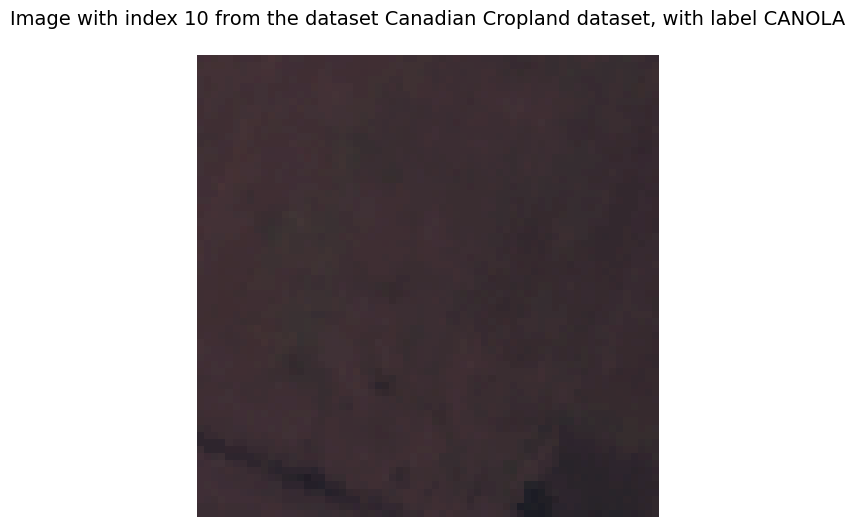

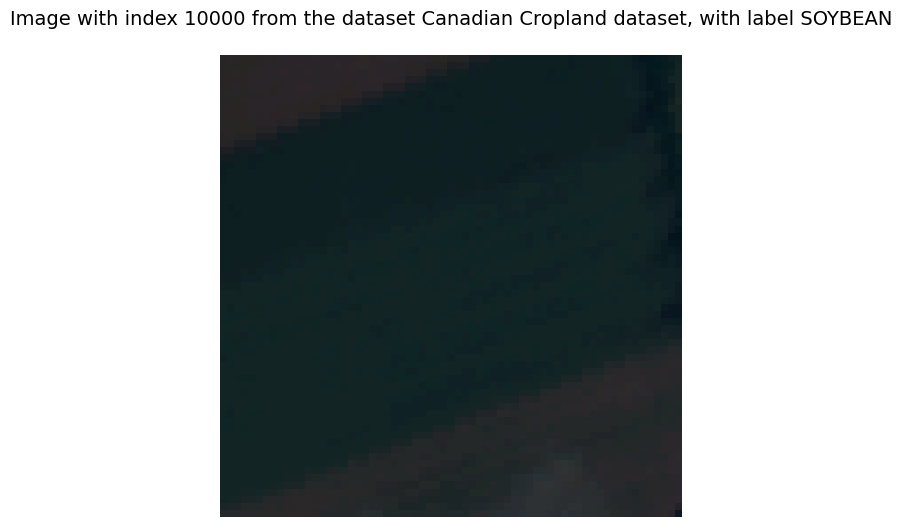

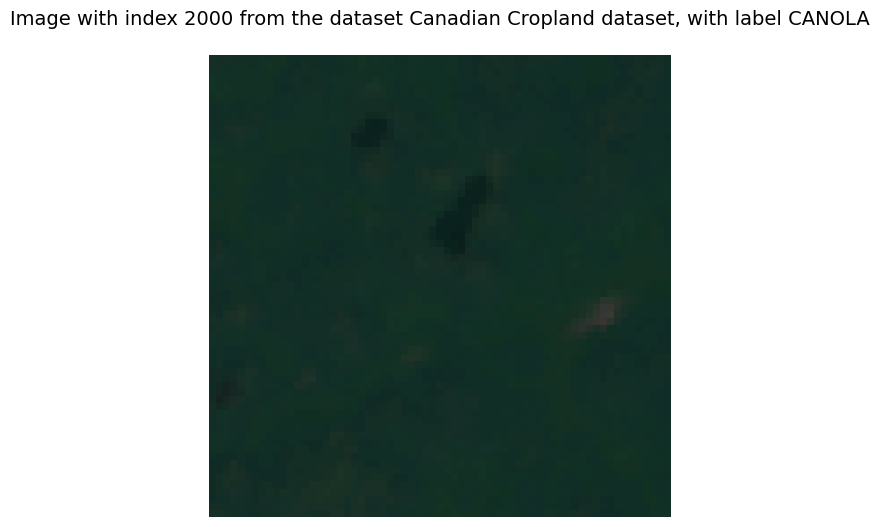

In [26]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(10000)
fig3 = dataset.show_image(2000)

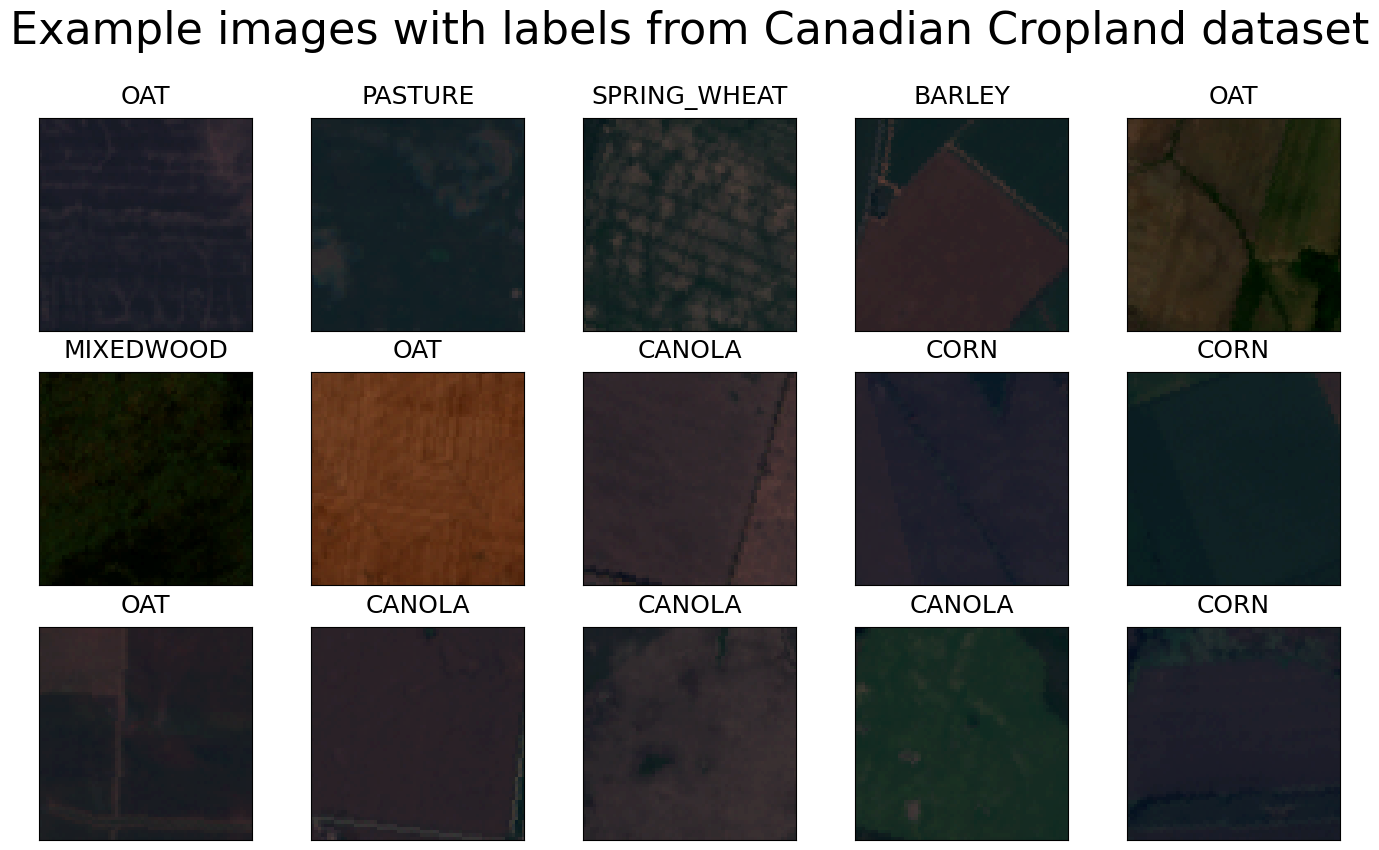

In [24]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [27]:
dataset.data_distribution_table()

,Label,Count
0,BARLEY,3751
1,CANOLA,7953
2,CORN,9016
3,MIXEDWOOD,3471
4,OAT,3369
5,ORCHARD,4614
6,PASTURE,6171
7,POTATO,3721
8,SOYBEAN,7145
9,SPRING_WHEAT,5754


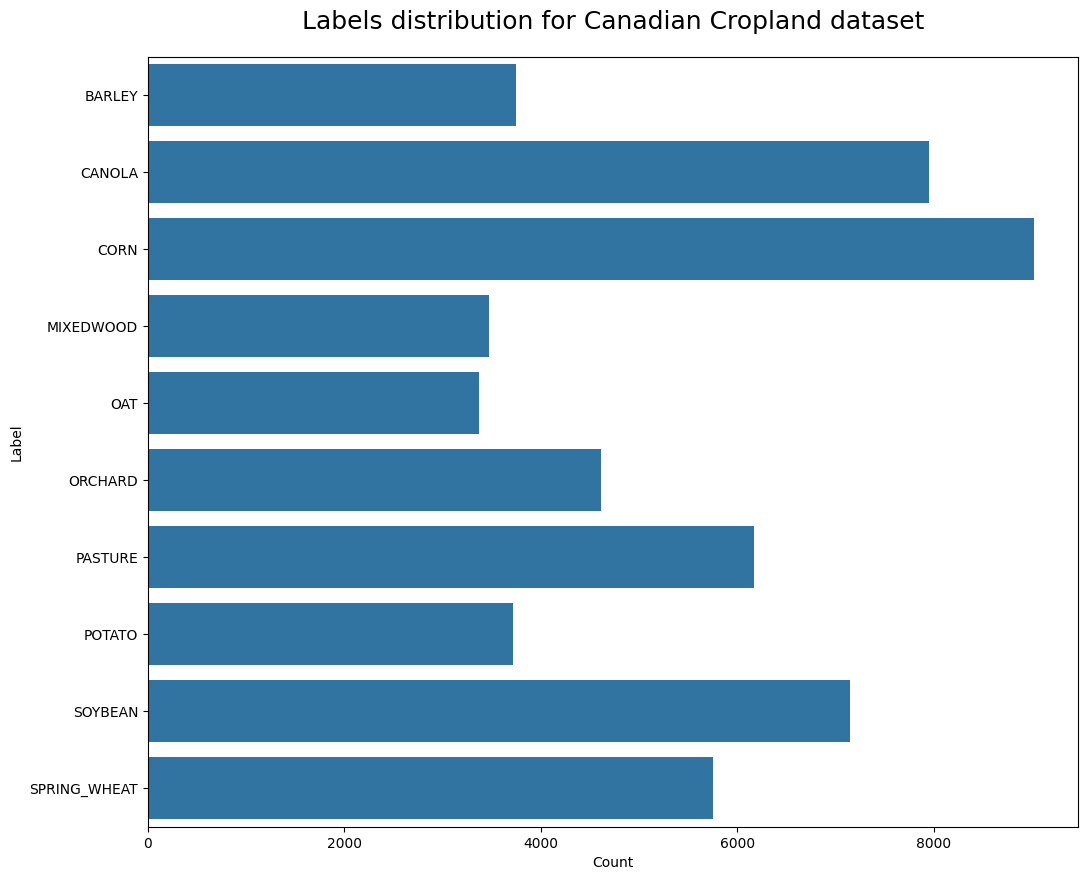

In [28]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/canadian_cropland/RGB/training/",
}

train_dataset = CanadianCroplandDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/canadian_cropland/RGB/validation/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = CanadianCroplandDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(54965, 11617)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/canadian_cropland/"
model_config = {
    "num_classes": 10, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-21 07:25:50,983 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-21 07:25:51,243 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-21 07:25:51,301 INFO Starting training.
training: 100%|██████████| 1718/1718 [23:46<00:00,  1.20it/s]
2025-05-21 07:49:38,523 INFO epoch: 1, time: 1427, loss:  1.29350
testing on train set: 100%|██████████| 1718/1718 [08:42<00:00,  3.29it/s]
2025-05-21 07:58:22,603 INFO Accuracy:0.6180842354225417, Precision Micro:0.6180842354225417, Precision Macro:0.6358726217119643, Precision Weighted:0.6184619232857544, Precision per Class:[0.49130988 0.68153863 0.57323669 0.99295527 0.58095638 0.96155517
 0.52078179 0.56880734 0.50972763 0.47785744], Recall Micro:0.6180842354225417, Recall Macro:0.619667091404008, Recall Weighted:0.6180842354225417, Recall per Class:[0.30898427 0.76637747 0.58773292 0.81215788 0.41110122 0.95947117
 0.6822233  0.81644719 0.45836249 0.393813  ], F1_score Micro:0.6180842354225411, F1_score Macro:0.6192375278954264, F1_score Weighted:0.6117021571532203, F1_score per Class:[0.37937807 0.72147254 0.5803943  0.89350238 0.48148792 0.96051204
 0.59066994 0.6704921

0.5061961704711078

## Predictions

2025-05-21 12:50:57,068 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/canadian_cropland/checkpoint.pth.tar
2025-05-21 12:50:57,724 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/canadian_cropland/checkpoint.pth.tar at epoch 11


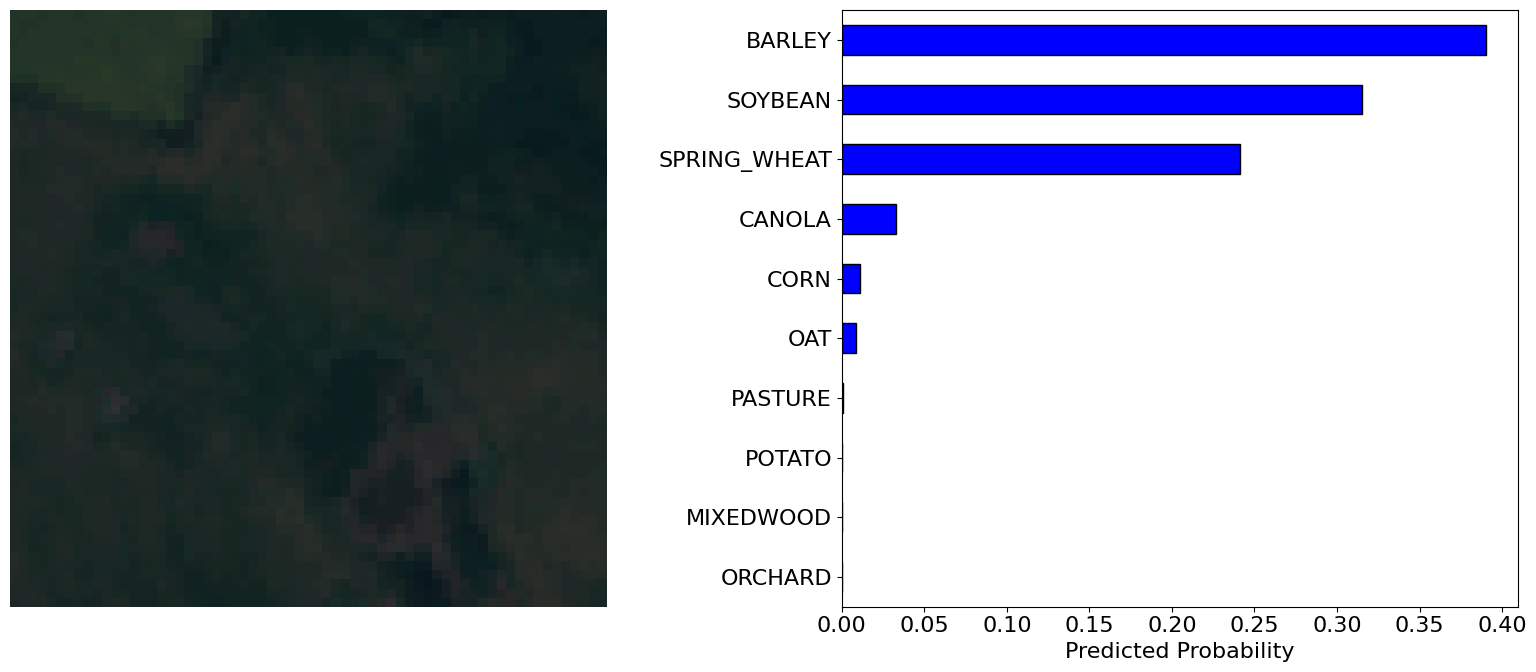

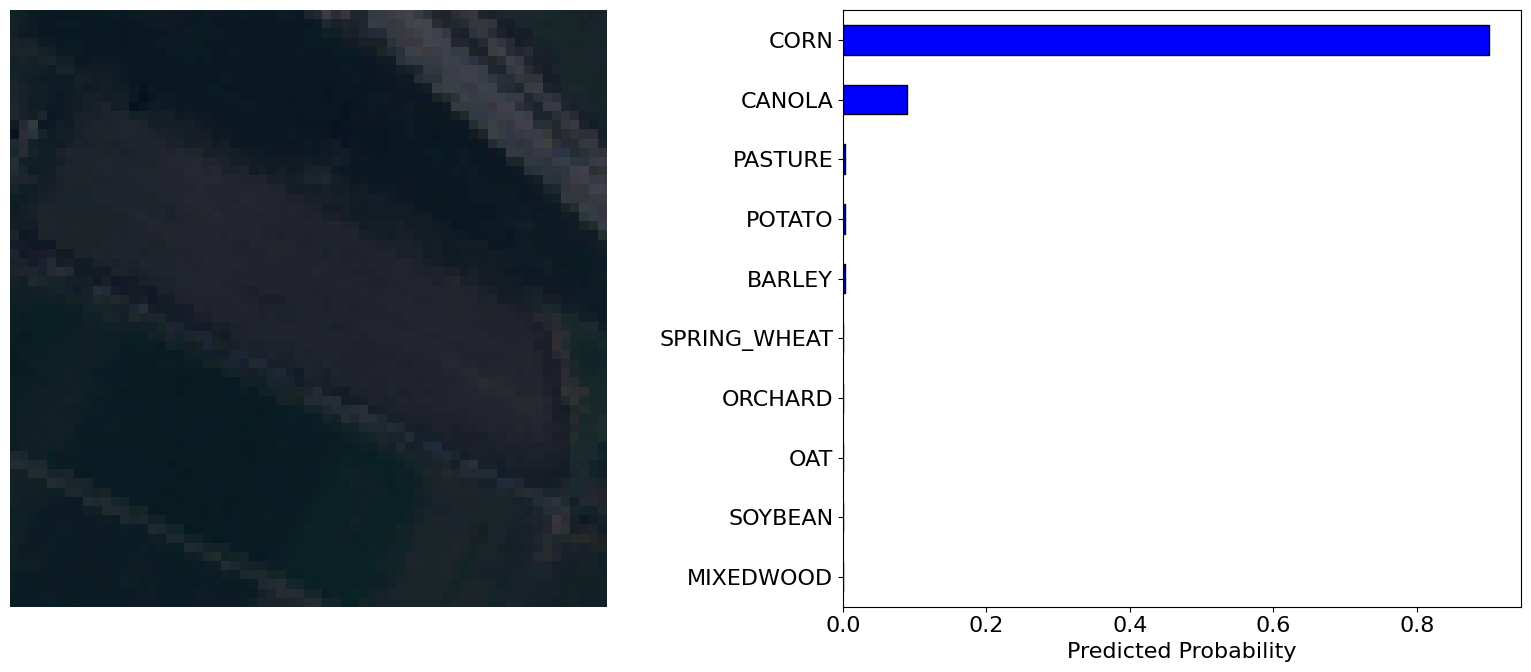

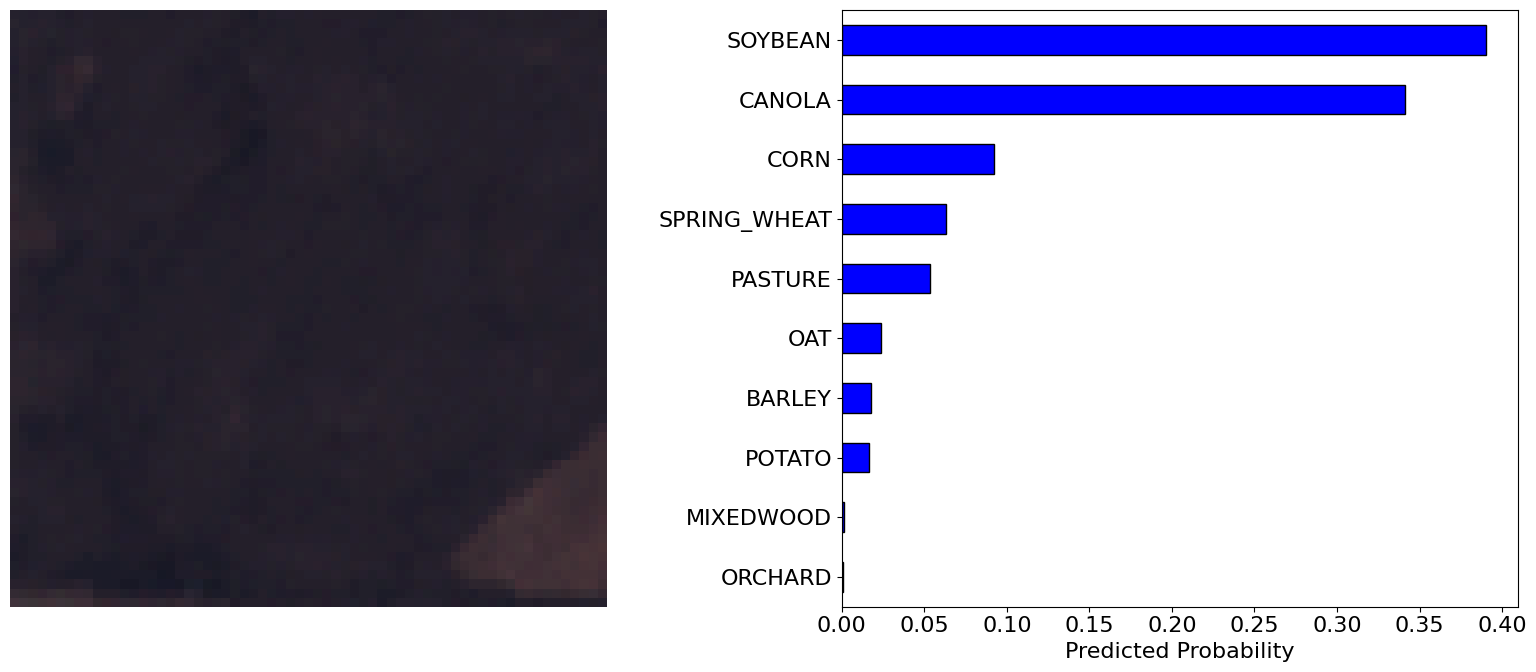

In [ ]:
labels = ["BARLEY","CANOLA","CORN","MIXEDWOOD","OAT","ORCHARD","PASTURE","POTATO","SOYBEAN","SPRING_WHEAT"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/canadian_cropland/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/canadian_cropland/RGB/test/BARLEY/POINT_12_201807_AB_BARLEY_RGB.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/canadian_cropland/RGB/test/POTATO/POINT_591_201809_BC_POTATO_RGB.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/canadian_cropland/RGB/test/SOYBEAN/POINT_702_201810_MB_SOYBEAN_RGB.png')
fig = model.predict_image(image, labels, transform)